# Inspect WAD dataset and create the subsets
## 1. Setup

In [1]:
import os, json, io, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

WAD_ROOT = Path("/Users/amynguyen/Documents/MQ/(26_2) FOSE7902 - Advanced STEM Research Placement/WAD/wad_dataset_v2")
DATA_DIR = WAD_ROOT / "src_data"
REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
OUT_DIR = REPO_ROOT / "data" / "subsets"
OUT_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
N_SUBSETS, SUBSET_SIZE = 5, 500
SUBSET_ROLES = {"dev_00": "development", "check_01": "check", "check_02": "check", "check_03": "check", "check_04": "check"}
rng = np.random.default_rng(SEED)

## 2. Files and structure

In [2]:
train = pd.read_json(WAD_ROOT / "train_v2.json", lines=True)
test = pd.read_json(WAD_ROOT / "test_alter_v2.json", lines=True)
test_qa = pd.read_json(WAD_ROOT / "test_QA_v2.json", lines=True)

clip = sorted(d for d in os.listdir(DATA_DIR) if d.endswith(".frame"))[0]
print("one clip folder:", sorted(os.listdir(DATA_DIR / clip)))
for name, df in [("train", train), ("test_alter", test), ("test_QA", test_qa)]:
    print(name, df.shape, list(df.columns))
print("train reminders:", train.alter.notna().sum(), "| train QA:", train.QA.notna().sum())
train.iloc[0]

one clip folder: ['0.jpg', '0.json', '1.jpg', '1.json', '2.jpg', '2.json', '3.jpg', '3.json', '4.jpg', '4.json', '5.jpg', '5.json', '6.jpg', '6.json', '7.jpg', '7.json', '8.jpg', '8.json', 'detect_0.jpg', 'detect_1.jpg', 'detect_2.jpg', 'detect_3.jpg', 'detect_4.jpg', 'detect_5.jpg', 'detect_6.jpg', 'detect_7.jpg', 'detect_8.jpg']
train (10146, 9) ['video', 'frame_path', 'weather_condition', 'area_type', 'danger_level', 'traffic_flow_rating', 'summary', 'alter', 'QA']
test_alter (1007, 8) ['video', 'frame_path', 'weather_condition', 'area_type', 'danger_level', 'traffic_flow_rating', 'summary', 'alter']
test_QA (134, 8) ['video', 'frame_path', 'weather_condition', 'area_type', 'danger_level', 'traffic_flow_rating', 'summary', 'QA']
train reminders: 8581 | train QA: 1565


video                  240918-youtube_short_fe880bc6cb4798233f2a42ad0...
frame_path             20240918-youtube_short_fe880bc6cb4798233f2a42a...
weather_condition                                                  Sunny
area_type                                                Pedestrian Path
danger_level                                                        High
traffic_flow_rating                                                 High
summary                on a pedestrian street, there are pedestrians ...
alter                  ahead there are pedestrians gathering in the m...
QA                                                                   NaN
Name: 0, dtype: object

## 3. Scene conditions (test)

In [3]:
for col in ["weather_condition", "area_type", "danger_level", "traffic_flow_rating"]:
    print(col, test[col].value_counts().to_dict())

weather_condition {'Sunny': 661, 'Night': 102, 'Cloudy': 91, 'Overcast': 61, 'Indoor': 50, 'Other': 42}
area_type {'Pedestrian Path': 631, 'Other': 149, 'Road': 144, 'Busy Street': 32, 'Shopping Mall': 22, 'Corridor': 18, 'Bicycle Lane': 9, 'Restaurant': 2}
danger_level {'High': 415, 'Low': 301, 'Mid': 291}
traffic_flow_rating {'Low': 510, 'High': 275, 'Mid': 222}


## 4. Visual samples

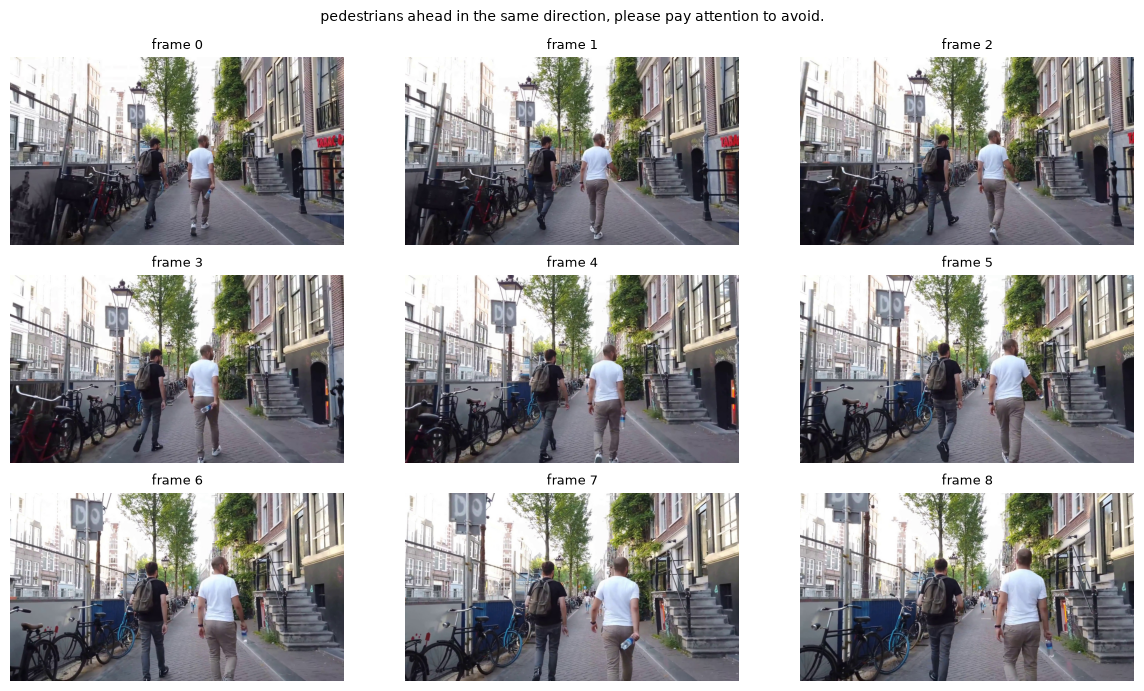

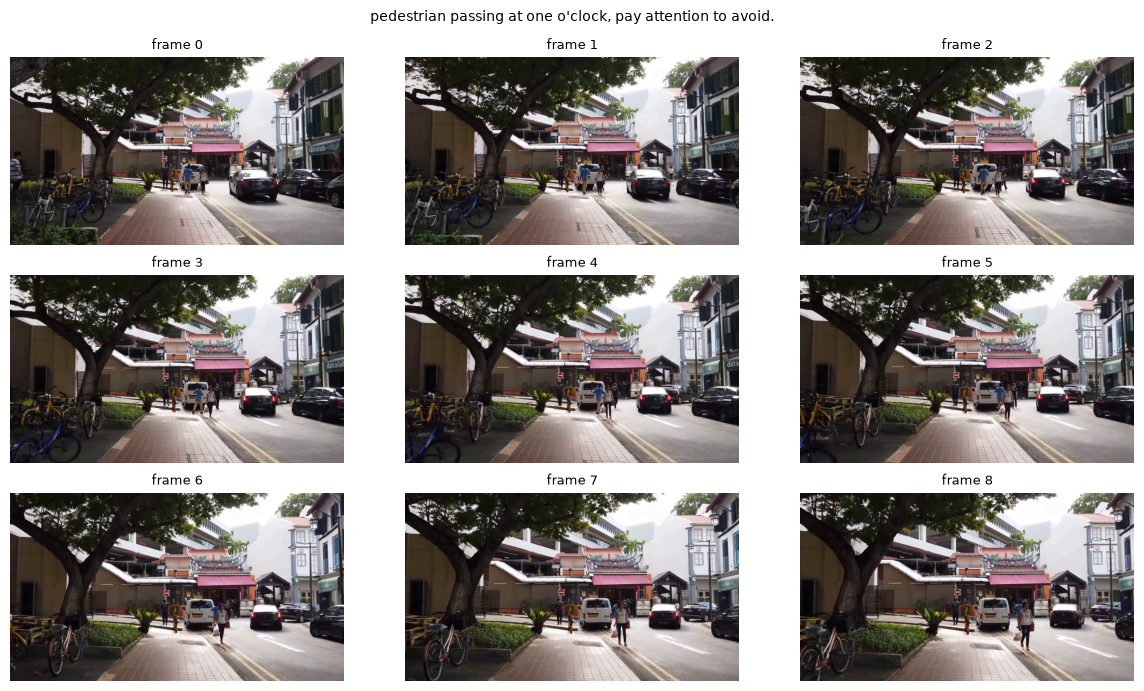

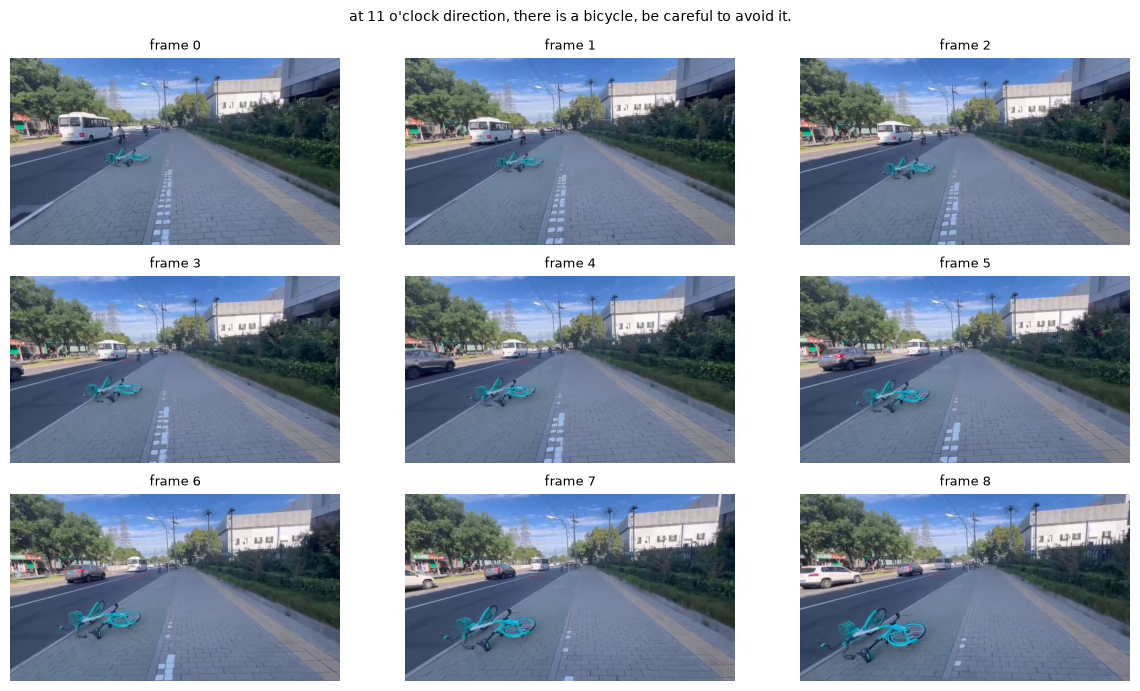

In [4]:
for _, row in test.sample(3, random_state=0).iterrows():
    fig, axs = plt.subplots(3, 3, figsize=(12, 7))
    for k, ax in enumerate(axs.flat):
        ax.imshow(Image.open(DATA_DIR / row.frame_path / f"{k}.jpg"))
        ax.set_title(f"frame {k}", fontsize=9)
        ax.axis("off")
    fig.suptitle(row.alter, fontsize=10)
    plt.tight_layout()
    plt.show()

## 5. Response type and the eligible pool

In [ ]:
for df in (train, test):
    df["source_id"] = df.frame_path.str.extract(r"([0-9a-f]{32})")[0].fillna(df.frame_path)
    df["has_reminder"] = df["alter"].fillna("").str.strip().ne("")
    df["all_keyframes"] = [all((DATA_DIR / fp / f"{k}.jpg").exists() for k in range(9)) for fp in df.frame_path]

# Response type from keywords (approximate, only used for balancing)
CLEAR = r"unobstructed|is clear|clear and safe|no obstacles?|without worry|safe to pass"
CLOCK = r"o'?\s*clock"
REDIRECT = r"\b(?:move|moving|walk|walking|go|going|turn|deviate|shift|head|keep)\w*\b[^.,;]{0,25}?\b(?:towards?|to|in|at)\s+(?:the\s+)?(?:\d{1,2}|one|two|three|nine|ten|eleven|twelve)\s*o'?\s*clock|\bturn (?:left|right)\b|\bstop\b|\bwait\b"
for df in (train, test):
    text = df["alter"].fillna("")
    df["response_type"] = np.select(
        [text.str.contains(CLEAR, case=False) & ~text.str.contains(CLOCK, case=False),
         text.str.contains(REDIRECT, case=False)],
        ["clear", "hazard_redirect"], "hazard_continue")

pool = train[train.has_reminder & train.all_keyframes & ~train.frame_path.duplicated()].copy()
pool["stratum"] = pool.danger_level + "|" + pool.response_type
print("eligible pool:", len(pool), "clips from", pool.source_id.nunique(), "source videos")
print(pool.response_type.value_counts().to_dict())

eligible pool: 8578 clips from 205 source videos
{'hazard_continue': 7036, 'hazard_redirect': 959, 'clear': 583}


## 6. WAD subsets (5 subsets with 500 videos each)
**Rules for the subsets**
- Reminder (`alter`) clips only, all 9 keyframes present, no duplicates.
- Each source video goes into one subset only.
- Subsets are balanced by danger level and response type (clear / hazard, keep going / hazard, change course).
- Test = all 1,007 `test_alter` clips, unchanged. Note: every test clip shares a source video with the training data, so dev_00 and test can show similar scenes (a limitation).

In [7]:
# Assign whole source videos to subsets, largest first to the least-filled subset
src_sizes = pool.groupby("source_id").size().sample(frac=1, random_state=SEED).sort_values(ascending=False, kind="stable")
names = list(SUBSET_ROLES)
load = {n: 0 for n in names}
src_to_subset = {}
for src, size in src_sizes.items():
    n = min(load, key=load.get)
    src_to_subset[src] = n
    load[n] += size
pool["subset_pool"] = pool.source_id.map(src_to_subset)

# In each subset, sample 500 clips with the pool's danger x response mix;
target_n = (pool.stratum.value_counts(normalize=True) * SUBSET_SIZE).round().astype(int)
target_n.iloc[0] += SUBSET_SIZE - target_n.sum()
pool["w"] = 1 / np.sqrt(pool.groupby("source_id").source_id.transform("size")) # weight 1/sqrt(clips per video) so long videos don't dominate

picked = []
for n in names:
    cand = pool[pool.subset_pool == n]
    chosen = []
    for s, k in target_n.items():
        c = cand[cand.stratum == s]
        key = rng.random(len(c)) ** (1 / c.w.to_numpy())
        chosen.append(c.iloc[np.argsort(-key)[:k]])
    chosen = pd.concat(chosen)
    short = SUBSET_SIZE - len(chosen)
    if short > 0:
        rest = cand.drop(chosen.index)
        key = rng.random(len(rest)) ** (1 / rest.w.to_numpy())
        chosen = pd.concat([chosen, rest.iloc[np.argsort(-key)[:short]]])
    picked.append(chosen.assign(subset=n))

subsets = pd.concat(picked)
assert (subsets.subset.value_counts() == SUBSET_SIZE).all()
assert subsets.groupby("source_id").subset.nunique().max() == 1
print(subsets.subset.value_counts().sort_index().to_dict())

{'check_01': 500, 'check_02': 500, 'check_03': 500, 'check_04': 500, 'dev_00': 500}


## 7. Test set and image orientation

In [8]:
test["subset"] = "test"
test["source_in_train"] = test.source_id.isin(set(train.source_id))
print("test clips:", len(test), "| sharing a source video with train:", test.source_in_train.sum())

for df in (subsets, test):
    df["width"], df["height"] = zip(*[Image.open(DATA_DIR / fp / "8.jpg").size for fp in df.frame_path])
    df["orientation"] = np.where(df.width >= df.height, "landscape", "portrait")

test clips: 1007 | sharing a source video with train: 1007


## 8. Balance across subsets and test

In [9]:
check = pd.concat([subsets, test], ignore_index=True)
for col in ["danger_level", "response_type", "orientation"]:
    print(pd.crosstab(check.subset, check[col], normalize="index").round(2), "\n")

danger_level  High   Low   Mid
subset                        
check_01      0.41  0.28  0.30
check_02      0.41  0.28  0.30
check_03      0.41  0.28  0.30
check_04      0.41  0.28  0.30
dev_00        0.41  0.28  0.30
test          0.41  0.30  0.29 

response_type  clear  hazard_continue  hazard_redirect
subset                                                
check_01        0.07             0.82             0.11
check_02        0.07             0.82             0.11
check_03        0.07             0.82             0.11
check_04        0.07             0.82             0.11
dev_00          0.07             0.82             0.11
test            0.06             0.82             0.12 

orientation  landscape  portrait
subset                          
check_01          0.76      0.24
check_02          0.86      0.14
check_03          0.88      0.12
check_04          0.84      0.16
dev_00            0.80      0.20
test              0.84      0.16 



## 9. Save (IDs and labels only)


In [11]:
COLS = ["frame_path", "source_id", "subset", "danger_level", "area_type", "traffic_flow_rating",
        "weather_condition", "response_type", "orientation", "width", "height"]

for name in names:
    subsets[subsets.subset == name][COLS].sort_values("frame_path").to_csv(OUT_DIR / f"wad_{name}.csv", index=False)
test[COLS + ["all_keyframes", "source_in_train"]].sort_values("frame_path").to_csv(OUT_DIR / "wad_test.csv", index=False)

## 10. Zip for Kaggle

In [ ]:
ZIP_DIR = WAD_ROOT.parent / "wad_subset_zips"
ZIP_DIR.mkdir(exist_ok=True)
MAX_SIDE, JPEG_QUALITY = 1280, 92

ann_all = pd.concat([train, test]).drop_duplicates("frame_path")
for name in names + ["test"]:
    manifest = pd.read_csv(OUT_DIR / f"wad_{name}.csv")
    with zipfile.ZipFile(ZIP_DIR / f"wad_{name}.zip", "w", compression=zipfile.ZIP_STORED) as z:
        z.write(OUT_DIR / f"wad_{name}.csv", f"wad_{name}/manifest.csv")
        recs = ann_all[ann_all.frame_path.isin(manifest.frame_path)]
        z.writestr(f"wad_{name}/annotations.jsonl", recs.to_json(orient="records", lines=True, force_ascii=False))
        for fp in manifest.frame_path:
            for k in range(9):
                im = Image.open(DATA_DIR / fp / f"{k}.jpg").convert("RGB")
                im.thumbnail((MAX_SIDE, MAX_SIDE))
                buf = io.BytesIO()
                im.save(buf, "JPEG", quality=JPEG_QUALITY)
                z.writestr(f"wad_{name}/frames/{fp}/{k}.jpg", buf.getvalue())